# What drives chances at the 2022 World Cup, and how Argentina and France fit the pattern

Reproduces every number and figure in the README, top to bottom from a clean clone. The first run
downloads about 230k events from StatsBomb open data and caches them in `data/`.

**Three stages:** (1) what drives chances across the tournament, (2) where Argentina and France sit,
(3) what changed in the final. Extra time is included throughout; only penalty shootouts are excluded.

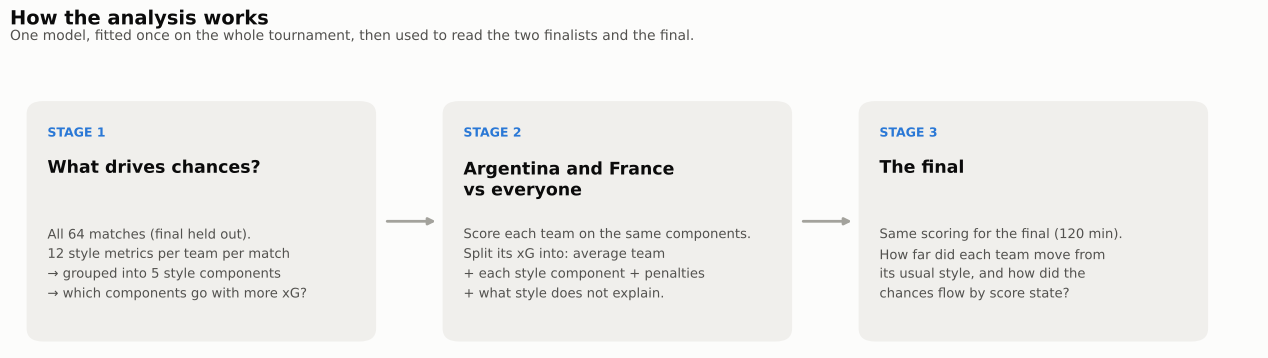

In [1]:
import sys; sys.path.insert(0, "../src")
import pandas as pd
import data, metrics as M, model, final, plots
pd.set_option("display.precision", 2, "display.width", 160)
plots.pipeline();

## Data: one row per team per match, all 120 minutes where played

In [2]:
ev = M.prepare(data.events())
fid = data.final_match_id()
tm = M.team_match_table(ev, data.matches())      # periods 1-4: extra time in, shootouts out
base, fin = tm[tm.match_id != fid], tm[tm.match_id == fid]
print(f"{ev.match_id.nunique()} matches, {len(ev):,} events -> {len(base)} team-match rows for the baseline")
print("matches that went to extra time:", int((tm.groupby('match_id').minutes.first() > 110).sum()))

64 matches, 234,637 events -> 126 team-match rows for the baseline
matches that went to extra time: 7


**Sanity checks:** goals per team match the shot data, and the final reads 3–3.

In [3]:
goals = ev[(ev.period < 5) & (ev.type == "Shot") & (ev.shot_outcome == "Goal")].groupby(["match_id", "team"]).size()
chk = tm.set_index(["match_id", "team"]).goals
print("goals match shot data for every team-match:", (chk == goals.reindex(chk.index, fill_value=0)).all())
fin[["team", "goals", "xg", "pen_xg", "minutes"]]

goals match shot data for every team-match: True


,team,goals,xg,pen_xg,minutes
126,Argentina,3,2.76,0.78,141.41
127,France,3,2.27,1.57,141.41


In [4]:
tm[tm.team == "Argentina"][["date", "stage", "opponent", "goals", "xg", "pen_xg", "minutes"]]

,date,stage,opponent,goals,xg,pen_xg,minutes
92,2022-11-22,Group Stage,Saudi Arabia,1,2.49,0.78,110.22
70,2022-11-26,Group Stage,Mexico,2,0.33,0.00,101.97
21,2022-11-30,Group Stage,Poland,2,3.08,0.78,99.10
100,2022-12-03,Round of 16,Australia,2,1.48,0.00,99.44
113,2022-12-09,Quarter-finals,Netherlands,2,1.94,0.78,139.85
120,2022-12-13,Semi-finals,Croatia,3,1.86,0.78,99.24
126,2022-12-18,Final,France,3,2.76,0.78,141.41


The 12 style metrics. None use shots or xG, so the target cannot leak into the inputs:

In [5]:
pd.DataFrame(M.METRICS, index=["pillar", "definition"]).T

,pillar,definition
possession_share,Build-up,Share of all passes in the match made by the team
passes_per_possession,Build-up,Open-play passes per team possession
pass_completion_under_pressure,Build-up,Completion rate of open-play passes made under...
progressive_passes_p90,Progression,Completed open-play passes that cut the distan...
progressive_carries_p90,Progression,Carries of 5+ units that cut the distance to g...
directness,Progression,Average forward gain (x) per open-play pass
long_ball_share,Progression,Share of open-play passes of 35+ units
field_tilt,Territory,Team share of both teams' passes made in the f...
crosses_per_entry,Territory,Open-play crosses per final-third entry
pressures_per_opp_possession,Pressing,Pressures per opponent possession


## Stage 1: what drives chances?

PCA groups the 12 metrics into 5 components; a regression then asks how each one moves
non-penalty xG per 90. Penalties are not a style trait, so they are left out of the target here
and added back as their own block in Stage 2.

In [6]:
b = model.fit(base)
print("variance explained by the 5 components:", round(b.explained.sum(), 2), b.explained.round(3).to_dict())
print("R²:", round(b.ols.rsquared, 3), "| average team xG/90:", round(b.average_xg, 2), "(of which penalties", round(b.mean_pen_p90, 2), ")")
b.effects.rename(index=model.NAMES).round(3)

variance explained by the 5 components: 0.85 {'PC1': 0.502, 'PC2': 0.132, 'PC3': 0.085, 'PC4': 0.069, 'PC5': 0.058}
R²: 0.359 | average team xG/90: 1.05 (of which penalties 0.11 )


,effect,lo,hi,p
Control,0.26,0.16,0.36,0.00e+00
Direct & wide,0.21,0.10,0.31,0.00e+00
Pressing volume,0.13,0.01,0.25,3.20e-02
Pressing height,-0.02,-0.12,0.07,6.78e-01
Ball-carrying,0.17,0.06,0.27,2.00e-03


What each component is made of (PCA loadings; larger magnitude = more weight):

In [7]:
b.loadings.rename(columns=model.NAMES).round(2)

,Control,Direct & wide,Pressing volume,Pressing height,Ball-carrying
possession_share,0.37,0.05,-0.11,-0.13,-0.09
passes_per_possession,0.35,-0.16,0.05,-0.05,0.15
pass_completion_under_pressure,0.24,-0.28,0.32,-0.37,-0.50
progressive_passes_p90,0.33,0.26,0.02,0.06,0.15
progressive_carries_p90,0.25,0.21,0.31,-0.19,0.67
directness,-0.33,0.34,-0.04,0.20,0.03
long_ball_share,-0.32,0.29,0.06,0.02,-0.15
field_tilt,0.38,0.16,-0.04,0.12,-0.11
crosses_per_entry,-0.11,0.51,0.47,-0.42,-0.26
pressures_per_opp_possession,-0.10,-0.30,0.74,0.49,0.09


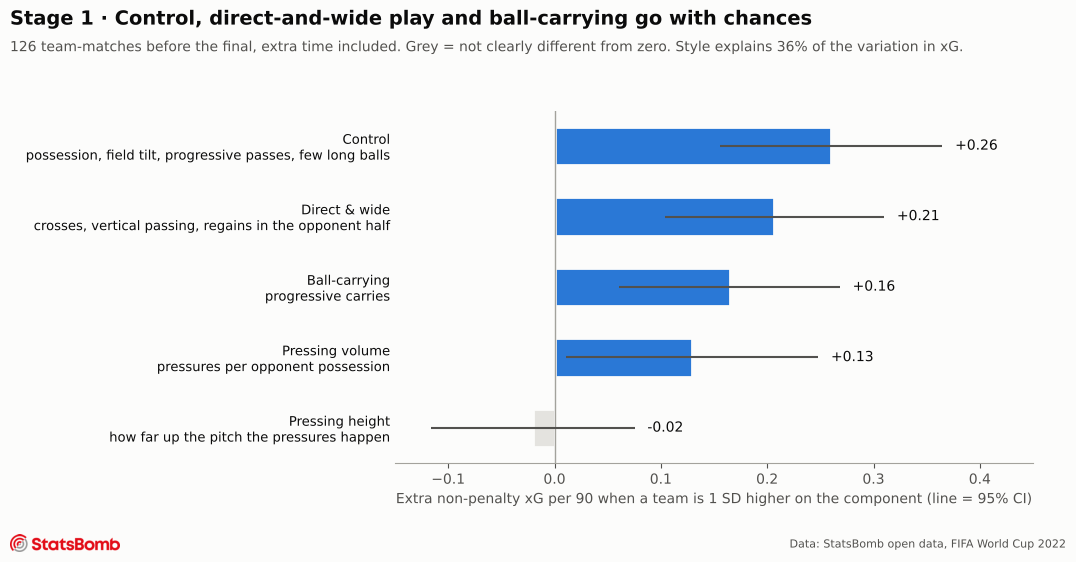

In [8]:
plots.stage1_drivers(b);

## Stage 2: Argentina and France vs everyone

In [9]:
bd = b.breakdown(base).join(base.team)
teams = bd.groupby("team").mean(numeric_only=True)
usual = b.components(base).join(base.team).groupby("team").mean()
ranks = usual.rank(ascending=False).astype(int).rename(columns=model.NAMES)
ranks["xG"] = teams.actual_xg.rank(ascending=False).astype(int)
ranks["xG predicted from style"] = teams.predicted_npxg.rank(ascending=False).astype(int)
print("Ranks among 32 teams (1 = highest):")
ranks.loc[["Argentina", "France"]].T

Ranks among 32 teams (1 = highest):


team,Argentina,France
Control,6,12
Direct & wide,31,21
Pressing volume,5,13
Pressing height,18,28
Ball-carrying,3,1
xG,3,5
xG predicted from style,6,4


In [10]:
teams.loc[["Argentina", "France"]].T

team,Argentina,France
average_team,1.05e+00,1.05e+00
Control,1.81e-01,6.44e-02
Direct & wide,-1.59e-01,-2.26e-02
Pressing volume,5.69e-02,1.26e-02
Pressing height,1.02e-03,9.00e-03
Ball-carrying,9.25e-02,1.91e-01
predicted_npxg,1.11e+00,1.19e+00
other,2.73e-02,2.13e-01
penalties,3.21e-01,-1.07e-01
actual_xg,1.57e+00,1.41e+00


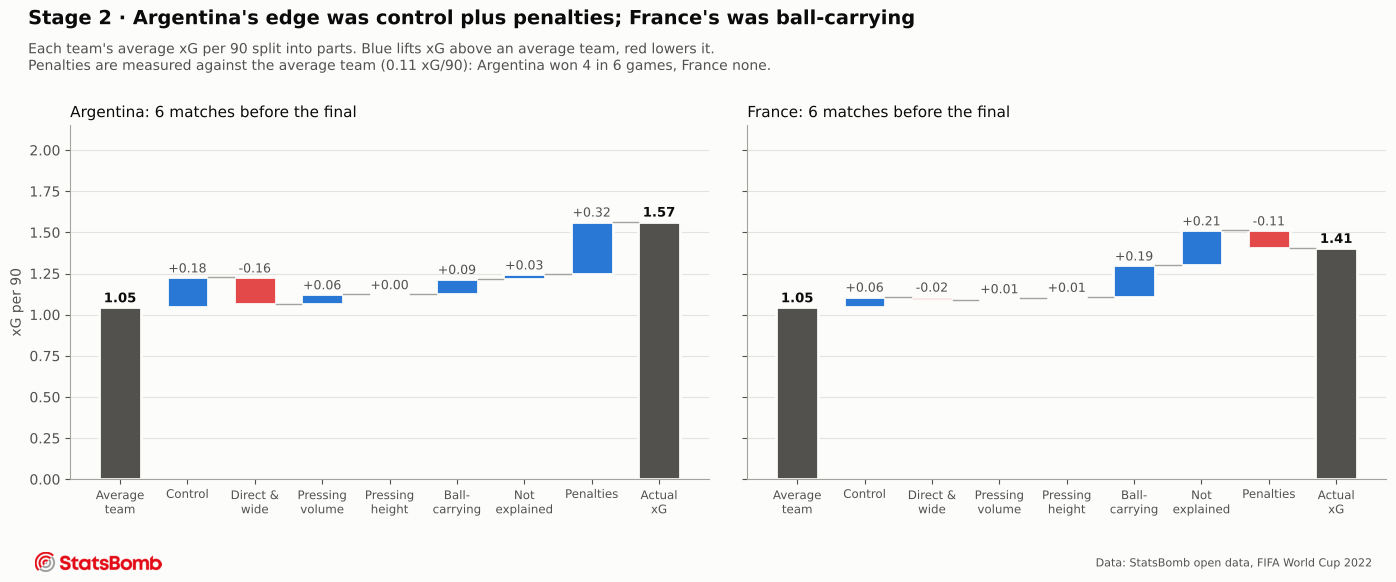

In [11]:
plots.stage2_breakdown(teams);

## Stage 3: the final (all 120 minutes)

In [12]:
fin_comp = b.components(fin).set_index(fin.team)
fin_bd = b.breakdown(fin).set_index(fin.team)
display(pd.concat({"usual": usual.loc[["Argentina", "France"]], "final": fin_comp}, axis=1).rename(columns=model.NAMES, level=1).T)
fin_bd.T

team                   Argentina  France
usual Control               1.72    0.61
      Direct & wide        -0.97   -0.14
      Pressing volume       0.45    0.10
      Pressing height      -0.05   -0.41
      Ball-carrying         0.47    0.97
final Control               0.02   -0.98
      Direct & wide         1.15   -0.91
      Pressing volume      -0.60    0.02
      Pressing height      -0.60    0.66
      Ball-carrying         0.76    0.17

team,Argentina,France
average_team,1.05e+00,1.05e+00
Control,1.98e-03,-1.04e-01
Direct & wide,1.89e-01,-1.50e-01
Pressing volume,-7.71e-02,2.25e-03
Pressing height,1.33e-02,-1.46e-02
Ball-carrying,1.49e-01,3.42e-02
predicted_npxg,1.22e+00,7.07e-01
other,4.17e-02,-2.58e-01
penalties,3.92e-01,8.91e-01
actual_xg,1.76e+00,1.45e+00


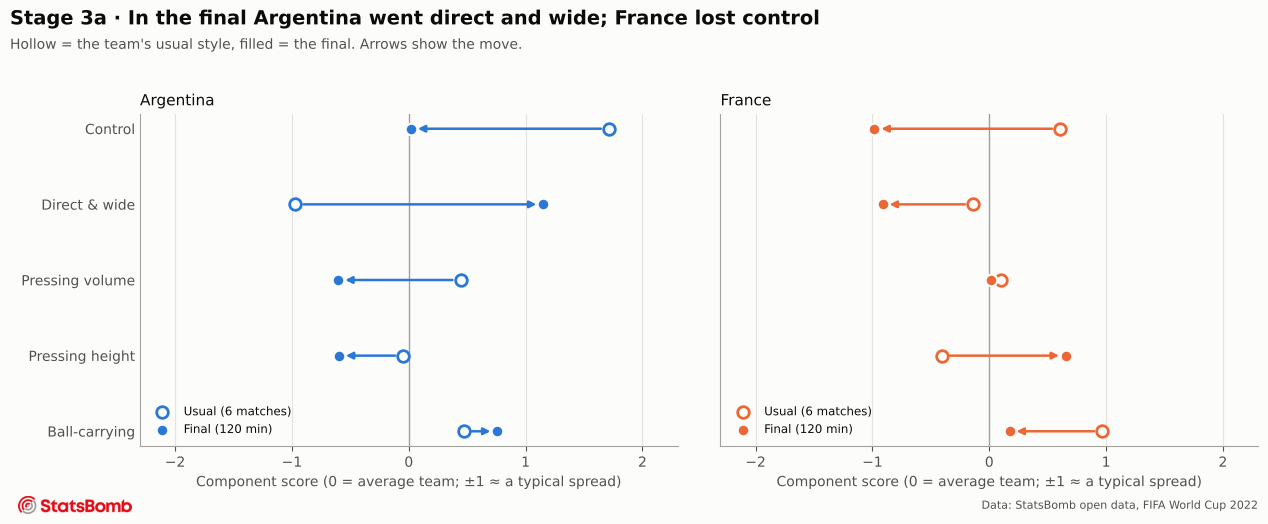

In [13]:
plots.stage3_style_shift(usual, fin_comp);

Each metric in the final as a z-score against the team's own earlier matches:

In [14]:
z = {t: (fin.set_index("team").loc[t, list(M.METRICS)] - base[base.team == t][list(M.METRICS)].mean())
         / base[base.team == t][list(M.METRICS)].std() for t in ["Argentina", "France"]}
pd.DataFrame(z).astype(float).round(1)

,Argentina,France
possession_share,-0.3,-0.6
passes_per_possession,-0.5,-1.4
pass_completion_under_pressure,-2.8,0.3
progressive_passes_p90,0.0,-1.3
progressive_carries_p90,-0.5,-1.5
directness,1.2,1.0
long_ball_share,0.0,0.1
field_tilt,0.0,-1.0
crosses_per_entry,1.3,-0.7
pressures_per_opp_possession,-1.6,0.4


Goals and substitutions straight from the event data (ground truth):

In [15]:
fe = ev[ev.match_id == fid]
display(final.goals(fe))
final.substitutions(fe)

,period,minute,second,team,player,shot_type
103561,1,22,24,Argentina,Lionel Andrés Messi Cuccittini,Penalty
103563,1,35,22,Argentina,Ángel Fabián Di María Hernández,Open Play
103570,2,79,24,France,Kylian Mbappé Lottin,Penalty
103571,2,80,59,France,Kylian Mbappé Lottin,Open Play
103583,4,107,58,Argentina,Lionel Andrés Messi Cuccittini,Open Play
103585,4,117,5,France,Kylian Mbappé Lottin,Penalty


,period,minute,second,team,player,substitution_replacement,substitution_outcome
103717,1,40,32,France,Ousmane Dembélé,Randal Kolo Muani,Tactical
103718,1,41,1,France,Olivier Giroud,Marcus Thuram,Tactical
103719,2,63,51,Argentina,Ángel Fabián Di María Hernández,Marcos Javier Acuña,Tactical
103720,2,70,27,France,Theo Bernard François Hernández,Eduardo Camavinga,Tactical
103721,2,70,29,France,Antoine Griezmann,Kingsley Coman,Tactical
103722,3,90,0,Argentina,Nahuel Molina Lucero,Gonzalo Ariel Montiel,Tactical
103723,3,95,10,France,Adrien Rabiot,Youssouf Fofana,Tactical
103724,3,101,37,Argentina,Rodrigo Javier De Paul,Leandro Daniel Paredes,Tactical
103725,3,101,49,Argentina,Julián Álvarez,Lautaro Javier Martínez,Tactical
103726,4,112,28,France,Raphaël Varane,Ibrahima Konaté,Injury


                    sum  count
team      penalty             
Argentina False    1.97     19
          True     0.78      1
France    False    0.71      8
          True     1.57      2


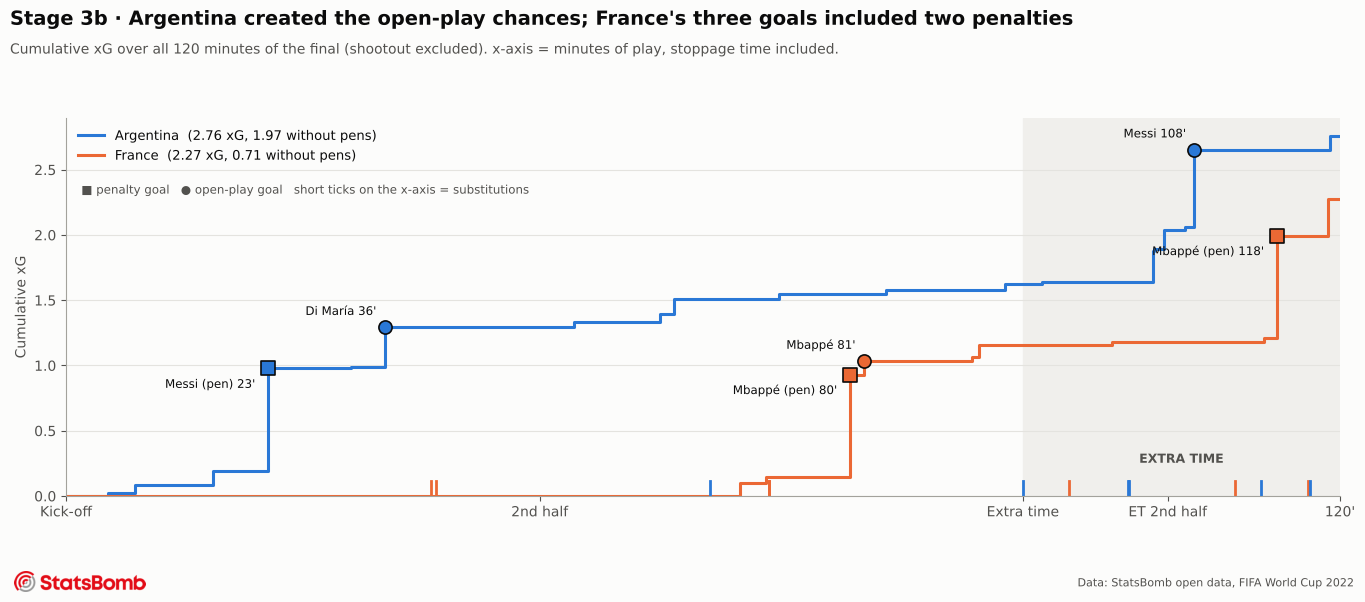

In [16]:
shots, subs, starts = final.xg_timeline(fe)
print(shots.groupby(["team", "penalty"]).xg.agg(["sum", "count"]))
plots.stage3_xg_race(shots, subs, starts);

The final by score state. Counts (`xg`, `minutes`) sit next to rates because the windows are short:

In [17]:
w = final.by_window(fe)
w[["minutes", "xg", "xg_p90", "possession_share", "pressure_height", "progressive_carries_p90"]]

minutes    xg  xg_p90  possession_share  pressure_height  progressive_carries_p90
window               team                                                                                        
0–22'\n0–0           Argentina    20.90  0.19    0.84              0.59            54.57                    12.92
                     France       20.90  0.00    0.00              0.41            52.01                     8.61
22–79'\nARG lead     Argentina    63.40  1.35    1.92              0.51            54.98                    17.04
                     France       63.40  0.15    0.21              0.49            57.95                    17.04
79–90'\nFRA comeback Argentina    19.22  0.07    0.34              0.50            38.15                     9.37
                     France       19.22  1.01    4.74              0.50            64.56                    28.10
91–120'\nextra time  Argentina    35.20  1.14    2.91              0.63            50.76                    15.34
                     France       35.20  1.11    2.85              0.37            50.71                     7.67